In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
project_folder = Path.home() / "Documents" / "shrimp-disease-detection"

data_folder = project_folder / "data" / "raw"

original_folder = data_folder / "ShrimpImages" / "ShrimpImages"

In [3]:
print(original_folder)

C:\Users\gutla\Documents\shrimp-disease-detection\data\raw\ShrimpImages\ShrimpImages


In [4]:
classes = ["BG", "Healthy", "WSSV", "WSSV_BG"]

for class_name in classes:
    folder = original_folder / class_name
    print(class_name, ":", len(list(folder.glob("*.jpg"))))

BG : 198
Healthy : 403
WSSV : 328
WSSV_BG : 220


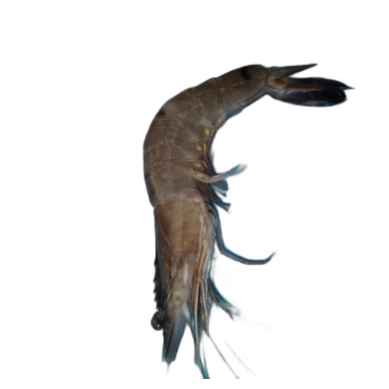

In [5]:
image_path = list((original_folder / "Healthy").glob("*.jpg"))[0]

image = Image.open(image_path)

plt.imshow(image)
plt.axis("off")
plt.show()

# dataset exploration

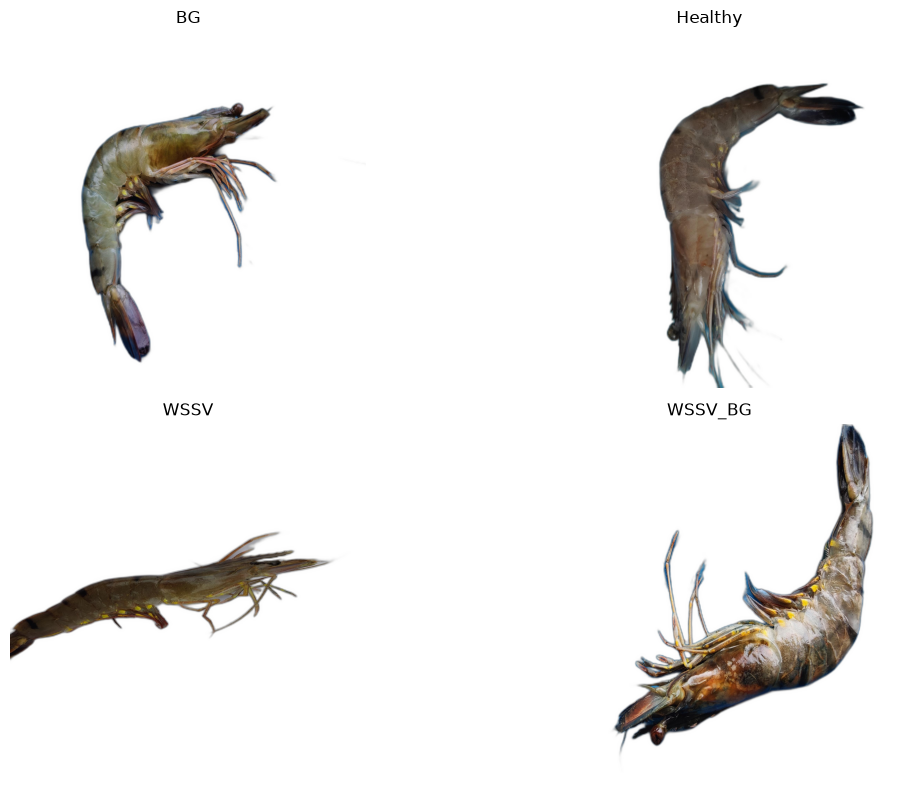

In [6]:
classes = ["BG", "Healthy", "WSSV", "WSSV_BG"]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    folder = original_folder / class_name
    image_path = list(folder.glob("*.jpg"))[0]
    image = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
print(image.size)

(2048, 2048)


In [8]:
print(image.mode)

RGB


In [9]:
import numpy as np

In [10]:
image_array = np.array(image)

In [11]:
print(image_array.shape)

(2048, 2048, 3)


In [12]:
print(image_array[0, 0])

[255 255 255]


In [13]:
print(image.size)
print(image.mode)

image_array = np.array(image)

print(image_array.shape)
print(image_array[0, 0])

(2048, 2048)
RGB
(2048, 2048, 3)
[255 255 255]


In [14]:
class_counts = {}

for class_name in classes:
    folder = original_folder / class_name
    count = len(list(folder.glob("*.jpg")))
    class_counts[class_name] = count

print(class_counts)

{'BG': 198, 'Healthy': 403, 'WSSV': 328, 'WSSV_BG': 220}


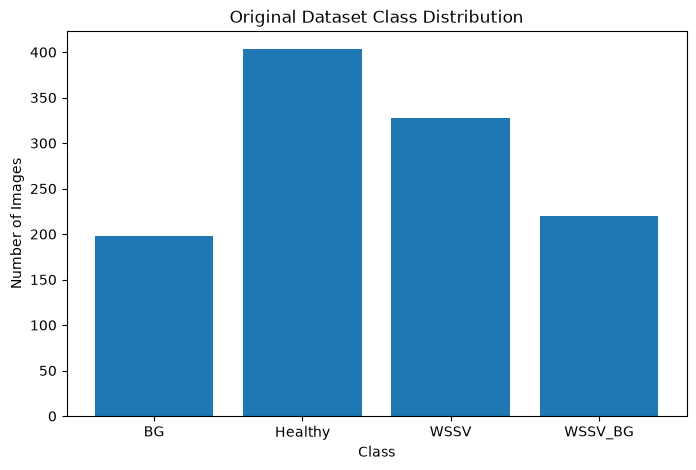

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Original Dataset Class Distribution")

plt.show()

In [16]:
for class_name in classes:
    folder = original_folder / class_name

    print("\n", class_name)

    for image_path in list(folder.glob("*.jpg"))[:5]:
        print(image_path.name)


 BG
BG-1-img-1.jpg
BG-1-img-2.jpg
BG-1-img-3.jpg
BG-10-img-1.jpg
BG-10-img-2.jpg

 Healthy
Healthy-1-img-1.jpg
Healthy-1-img-2.jpg
Healthy-1-img-3.jpg
Healthy-10-img-1.jpg
Healthy-10-img-2.jpg

 WSSV
WSSV-1-img-1.jpg
WSSV-1-img-2.jpg
WSSV-1-img-3.jpg
WSSV-10-img-1.jpg
WSSV-10-img-2.jpg

 WSSV_BG
WSSV_BG-1-img-1.jpg
WSSV_BG-1-img-2.jpg
WSSV_BG-1-img-3.jpg
WSSV_BG-10-img-1.jpg
WSSV_BG-10-img-2.jpg


In [17]:
image_path = list((original_folder / "BG").glob("*.jpg"))[0]

filename = image_path.stem

print("Filename:", filename)

parts = filename.split("-")

print("Parts:", parts)

source_id = "-".join(parts[:2])

print("Source ID:", source_id)

Filename: BG-1-img-1
Parts: ['BG', '1', 'img', '1']
Source ID: BG-1


In [18]:
import pandas as pd

splits_folder = project_folder / "data" / "splits"

train_df = pd.read_csv(splits_folder / "train.csv")

print(train_df.head())

  class         filename  source_id  \
0    BG   BG-1-img-1.jpg          1   
1    BG   BG-1-img-2.jpg          1   
2    BG   BG-1-img-3.jpg          1   
3    BG  BG-11-img-1.jpg         11   
4    BG  BG-11-img-2.jpg         11   

                                                path  split  
0  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
1  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
2  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
3  data\raw\ShrimpImages\ShrimpImages\BG\BG-11-im...  train  
4  data\raw\ShrimpImages\ShrimpImages\BG\BG-11-im...  train  


In [19]:
print(train_df.head())

  class         filename  source_id  \
0    BG   BG-1-img-1.jpg          1   
1    BG   BG-1-img-2.jpg          1   
2    BG   BG-1-img-3.jpg          1   
3    BG  BG-11-img-1.jpg         11   
4    BG  BG-11-img-2.jpg         11   

                                                path  split  
0  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
1  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
2  data\raw\ShrimpImages\ShrimpImages\BG\BG-1-img...  train  
3  data\raw\ShrimpImages\ShrimpImages\BG\BG-11-im...  train  
4  data\raw\ShrimpImages\ShrimpImages\BG\BG-11-im...  train  


In [20]:
print("Training images:", len(train_df))

val_df = pd.read_csv(splits_folder / "val.csv")
test_df = pd.read_csv(splits_folder / "test.csv")

print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 794
Validation images: 174
Test images: 181


In [21]:
train_sources = set(train_df["source_id"])
val_sources = set(val_df["source_id"])
test_sources = set(test_df["source_id"])

print("Train ∩ Validation :", len(train_sources & val_sources))
print("Train ∩ Test       :", len(train_sources & test_sources))
print("Validation ∩ Test  :", len(val_sources & test_sources))

Train ∩ Validation : 48
Train ∩ Test       : 45
Validation ∩ Test  : 17


In [22]:
train_sources = set(
    zip(train_df["class"], train_df["source_id"])
)

val_sources = set(
    zip(val_df["class"], val_df["source_id"])
)

test_sources = set(
    zip(test_df["class"], test_df["source_id"])
)

print("Train ∩ Validation :", len(train_sources & val_sources))
print("Train ∩ Test       :", len(train_sources & test_sources))
print("Validation ∩ Test  :", len(val_sources & test_sources))

Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0


In [23]:
augmented_folder = data_folder / "Augmented_shrimp"

for class_name in classes:
    folder = augmented_folder / class_name

    count = len(list(folder.glob("*.jpg")))

    print(class_name, ":", count)

BG : 500
Healthy : 500
WSSV : 500
WSSV_BG : 500


In [24]:
original_image = original_folder / "Healthy" / "Healthy-16-img-2.jpg"

augmented_image = augmented_folder / "Healthy" / "aug_0_Healthy-16-img-2.jpg"

print("Original exists :", original_image.exists())
print("Augmented exists:", augmented_image.exists())

Original exists : True
Augmented exists: True


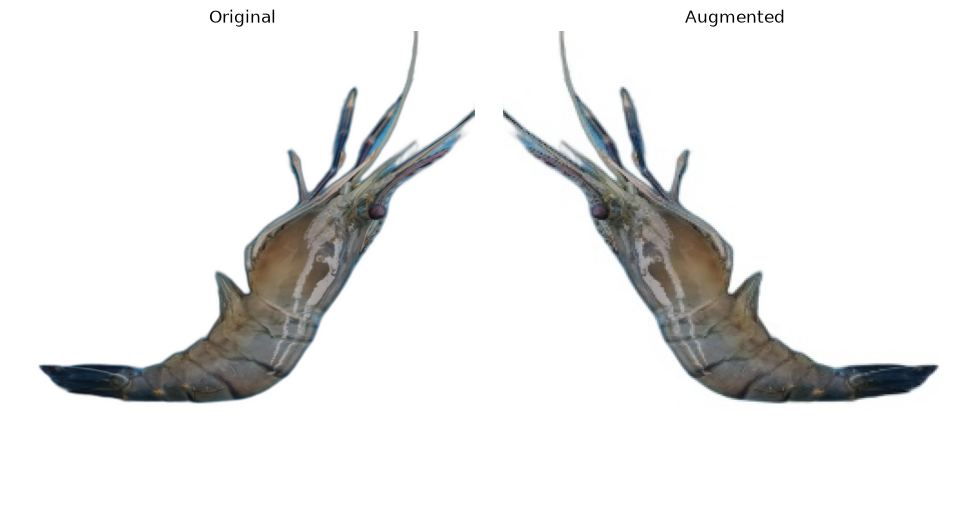

In [25]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(Image.open(original_image))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(Image.open(augmented_image))
plt.title("Augmented")
plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
augmented_folder = data_folder / "Augmented_shrimp"

augmented_path = list(
    (augmented_folder / "Healthy").glob("aug_*.jpg")
)[0]

print("Augmented filename:")
print(augmented_path.name)

# Remove "aug_" from the beginning
original_name = augmented_path.name[len("aug_"):]

print("\nOriginal filename:")
print(original_name)

# Extract source group
parts = Path(original_name).stem.split("-")

source_group = "-".join(parts[:2])

print("\nSource group:")
print(source_group)

Augmented filename:
aug_0_Healthy-16-img-2.jpg

Original filename:
0_Healthy-16-img-2.jpg

Source group:
0_Healthy-16


In [28]:
filename = "aug_0_Healthy-16-img-2.jpg"

original_name = filename.split("_", 2)[2]

parts = Path(original_name).stem.split("-")

source_group = "-".join(parts[:2])

print("Original filename:", original_name)
print("Source group:", source_group)

Original filename: Healthy-16-img-2.jpg
Source group: Healthy-16
